# Семинар 4.
## R2D2

In [4]:
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
# import nutpie # почему-то не подгружается, мб из-за рабочего WIFI
import pymc as pm
import scipy.special as sp
import scipy.stats as st
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

g++ not available, if using conda: `conda install gxx`


In [ ]:
# данные по калифорнийскому жилью
housing = fetch_california_housing(as_frame=True)

In [ ]:
data = housing["data"].copy()
target = housing["target"]
non_negative_variables = [ # сделать голосование на тему того, какие переменные наиболее значимы; потом это пойдет в фи как веса
    "MedInc", 
    "HouseAge",
    "AveRooms", 
    "AveBedrms",
    "Population",
    "AveOccup",
]
data[non_negative_variables] = np.log1p(data[non_negative_variables])
target = np.log(target)

In [36]:
Xscaler = StandardScaler()
Yscaler = StandardScaler()
X = Xscaler.fit_transform(data.values)
Y = Yscaler.fit_transform(target.values[:, None]).ravel()

### R2

Предполагаем, что на наших данных должнен быть в диапазоне 0.6-0.8

## Важность фичей (?)

In [37]:
X.shape, Y.shape

((20640, 8), (20640,))

In [38]:
data.columns.size

8

In [ ]:
p = X.shape[1]
phi_students = [] # заполнить

with pm.Model(
    coords=dict(
        variable=list(data.columns), 
        observation=np.arange(X.shape[0])
    )
) as model:
    # X_data = pm.Data("X", X, dims=("observation", "variable"))
     
    intercept = pm.Normal("intercept", 0, 0.05) # можно обсудить со студентами, какие параметры берем именно такие, сделать реверанс к лекции
    σ = pm.LogNormal("σ", 0, 0.05)
    

    R2 = pm.Beta("R2", mu=0.6, sigma=0.2)
    ϕ = pm.Dirichlet("ϕ", np.ones(p), dims="variable") # инициализация; если есть конкретные веса, то вставляем их сюда, только надо не забыть их завести как отдельную переменную phi_students
    
    model_σ = σ * R2 ** .5 
    resid_σ = σ * (1 - R2) ** .5
    
    β = pm.Normal("β", 0, model_σ * ϕ ** .5, dims="variable") # смотрим на модельную дисперсию, а потом на дисперсию отдельных переменных, которая зависит от весов 
    
    μ = intercept + X @ β # среднее предсказание модели
    
    pm.Normal("obs", μ, resid_σ, dims="observation", observed=Y) # сгенерированные наблюдения

SyntaxError: invalid syntax (1526002749.py, line 2)

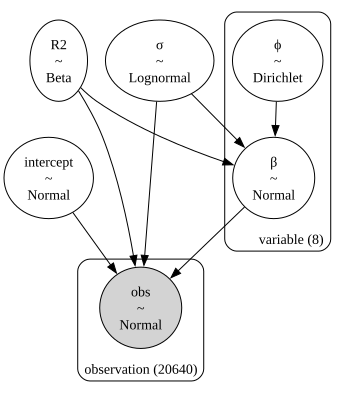

In [ ]:
pm.model_to_graphviz(model)

In [43]:
with model:
    trace = pm.sample()

NUTS[nutpie]: [intercept, σ, R2, ϕ, β]


Output()

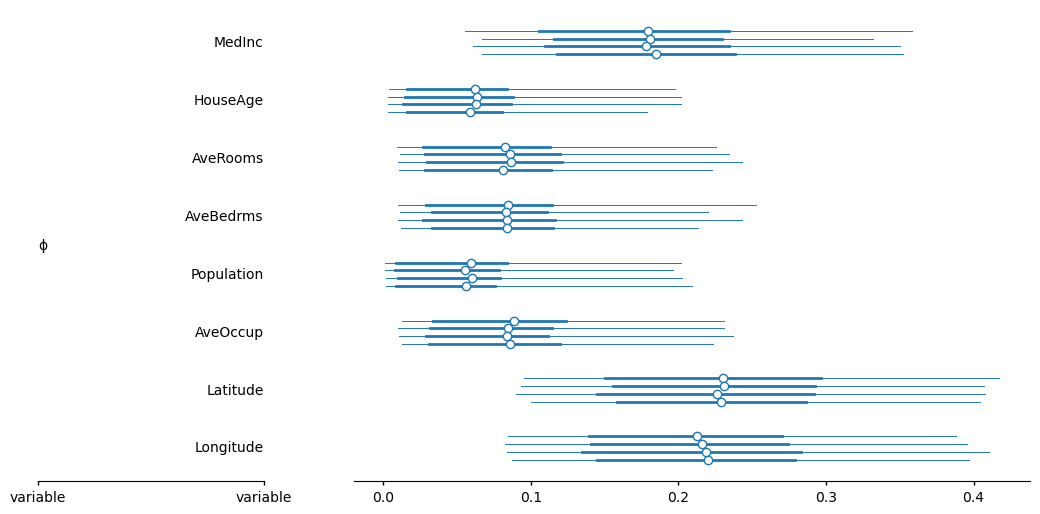

In [44]:
az.plot_forest(trace, var_names=["ϕ"]);

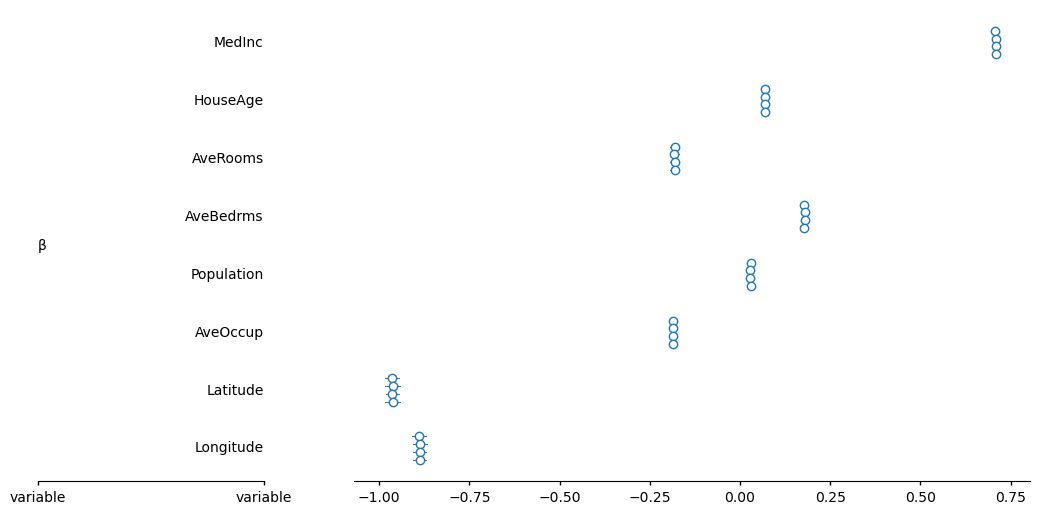

In [45]:
az.plot_forest(trace, var_names=["β"]);

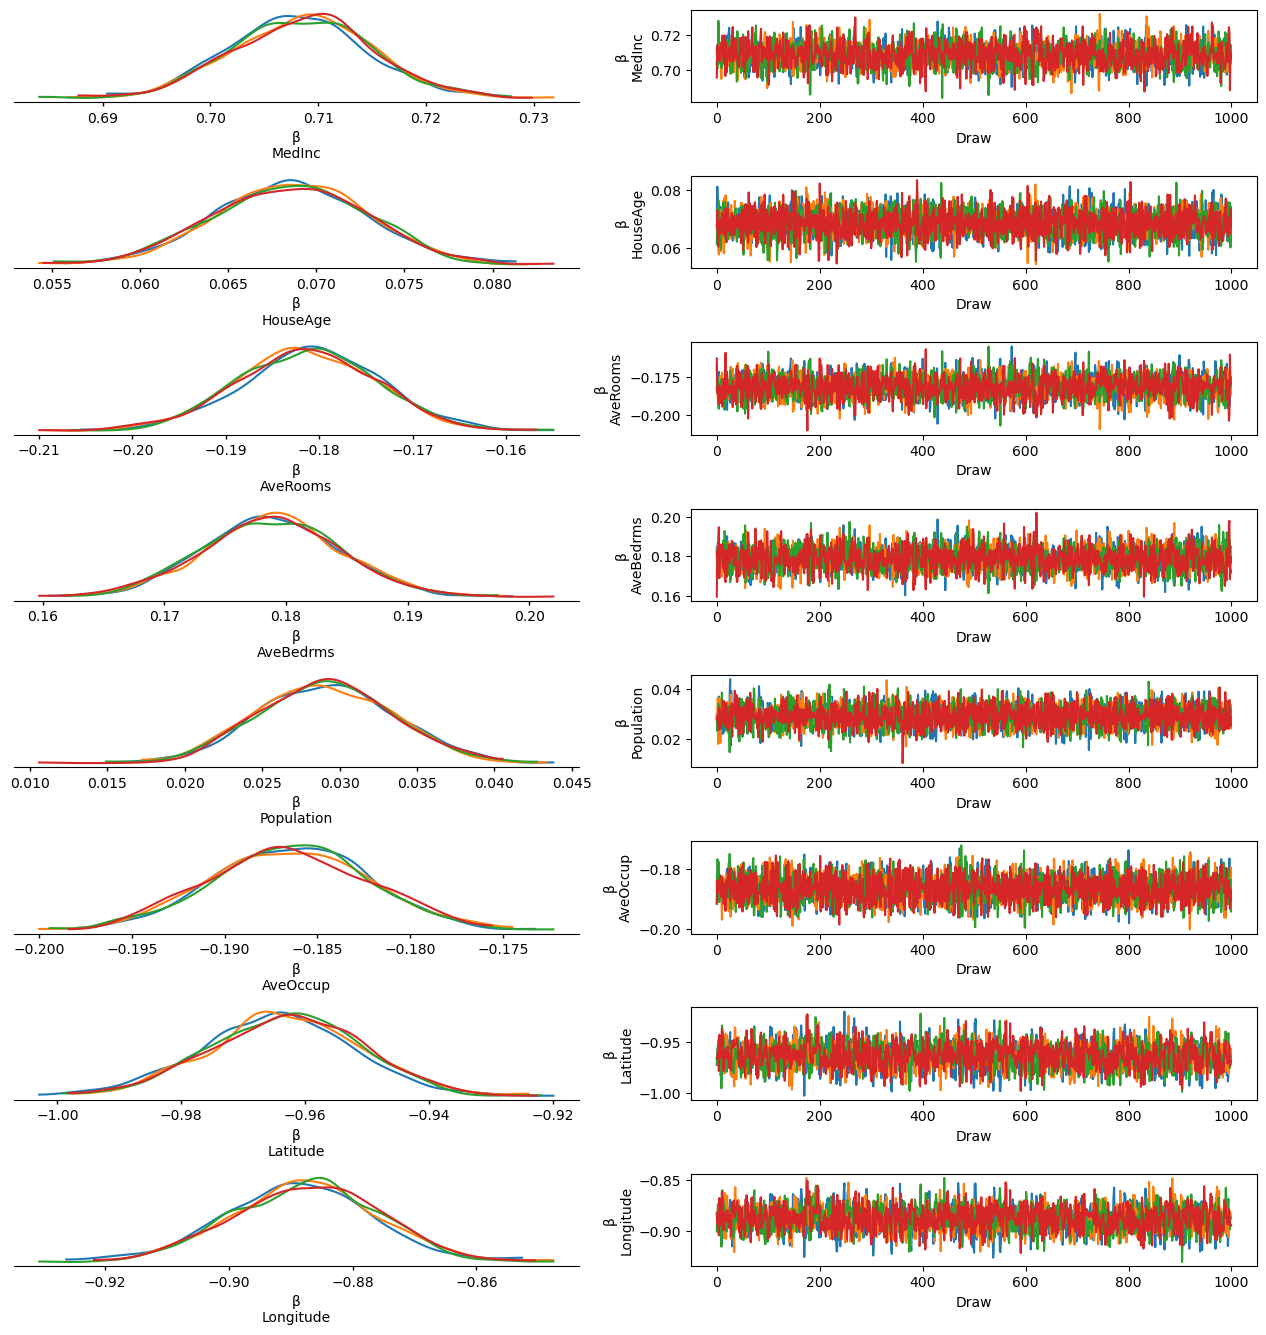

In [47]:
az.plot_trace_dist(trace, var_names=["β"], compact=False);
plt.tight_layout()

In [48]:
data.columns[:-2]

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population',
       'AveOccup'],
      dtype='object')

In [ ]:
float(X[:, -2:].min()), float(X[:, -2:].max()) # коориднаты домов, потребуются нам далее

(-2.3859923416733877, 2.9580676211031953)

In [ ]:
M = int(1.75 * (4 * 1.2) / 0.1) # оптимальное число векторов для гауссовского процесса
M

84

In [53]:
# Добавляем в модель гауссовский процесс
# Нам оно понадобиться, чтобы учитывать пространственная зависимость в данных
# В целом, можно рассказать немного про пространственные модели, но не суперглубоко, т.к. это отдельный курс
# Сделать связь с Байесом

In [ ]:
#!g1.1
with pm.Model(coords=dict(
    component=[*data.columns[:-2], *map(str, range(10)), "GP"],
    variable=[*data.columns[:-2], *map(str, range(10))],
    observation=range(X.shape[0])
)) as model_gp:
    # common 
    intercept = pm.Normal("intercept", 0, 0.05)
    σ = pm.LogNormal("σ", 0, 0.05)
    # variable and regression
    R2 = pm.Beta("R2", mu=0.6, sigma=0.2)
    ϕ = pm.Dirichlet("ϕ", [1]*6+[1]*10+[1], dims="component")
    
    model_σ = σ * R2 ** .5
    resid_σ = σ * (1 - R2) ** .5
    
    β = pm.Normal("β", 0, model_σ * ϕ[:-1] ** .5, dims="variable")
    
    μ = intercept + X[:, :-2] @ β
    
    Spatial = X[:, -2:] 
    
    ls = pm.Gamma("ls", mu=1, sigma=0.5)
    cov = pm.gp.cov.ExpQuad(2, ls=ls) * (model_σ ** 2 * ϕ[-1])
    gp = pm.gp.HSGP([M, M], c=1.2, drop_first=True, cov_func=cov)
    spatial_effect = gp.prior("spatial_effect", Spatial)
    pm.Normal("obs", μ + spatial_effect, resid_σ, dims="observation", observed=Y)